# Exercise 03 — Multiple Linear Regression

**M.Sc. Data Science · I Semester · Machine Learning Lab**  
**Department Number:** 26-PDS-011 · **Student:** Thenmozhi K

## Aim
Predict house prices from several property features using Multiple Linear Regression and evaluate the model with regression metrics.

## Dataset
Expected path: `Dataset/Housing.csv`. Obtain the dataset from its authorised source and place it at the path expected by the original program. See the [dataset guide](../datasets/README.md).

## Algorithm / Workflow
1. Load and inspect Housing.csv.
2. Encode categorical columns with LabelEncoder.
3. Separate predictors and price target.
4. Split 80:20 with random_state=42.
5. Train LinearRegression and predict test prices.
6. Calculate MAE, MSE, RMSE, R², adjusted R², MAPE, explained variance and maximum error.
7. Display intercept, coefficients and a sample prediction.
8. Plot actual versus predicted prices.

## Implementation
The following code is copied from the existing `ex-03.py` program and divided into notebook cells for interactive execution. The original Python file has not been modified.

> Run cells from top to bottom. Outputs and charts are generated when the cells are executed in an environment with the required dataset and dependencies.

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB

========== Regression Evaluation ==========
Mean Absolute Error (MAE): 979679.69
Mean Squared Error (MSE): 1771751116594.03
Root Mean Squared Error (RMSE): 1331071.42
R² Score: 0.6495

/tmp/ipykernel_2272/2979253034.py:26: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
/opt/hostedtoolcache/Python/3.12.15/x64/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


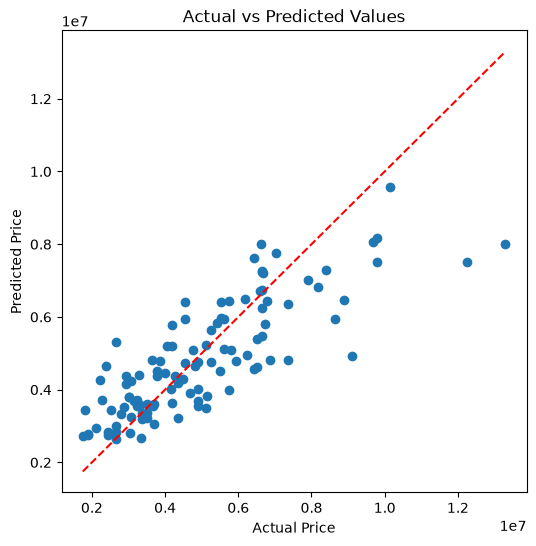

In [1]:
# EXERCISE – 03 (MULTIPLE LINEAR REGRESSION)

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    explained_variance_score,
    max_error
)

data = "https://raw.githubusercontent.com/thenmozhi269/machine_learning_lab/refs/heads/main/datasets/Housing.csv"

df= pd.read_csv(data)

df.head()

df.info()

le = LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col])

X = df.drop("price", axis=1)
y = df["price"]

x1, x2, y1, y2 = train_test_split(X, y,test_size=0.2,random_state=42)

model = LinearRegression()
model.fit(x1, y1)

y_pred = model.predict(x2)
y_pred

mae = mean_absolute_error(y2, y_pred)
mse = mean_squared_error(y2, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y2, y_pred)
mape = mean_absolute_percentage_error(y2, y_pred)
evs = explained_variance_score(y2, y_pred)
maxerr = max_error(y2, y_pred)

n = x2.shape[0]      # Number of observations
p = x2.shape[1]      # Number of predictors

adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print("\n========== Regression Evaluation ==========")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")
print(f"Adjusted R² Score: {adj_r2:.4f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.4f}")
print(f"Explained Variance Score: {evs:.4f}")
print(f"Maximum Error: {maxerr:.2f}")

print("\nIntercept:")
print(model.intercept_)

print("\nCoefficients:")
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
print(coef)

new_house = [[5000,3,2,2,1,1,0,1,0,1,0,1]]

prediction = model.predict(new_house)

print("\nPredicted House Price:", prediction[0])

import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(y2, y_pred)
plt.plot([y2.min(), y2.max()],
         [y2.min(), y2.max()],
         'r--')

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Values")
plt.show()


## Result summary from the practical record
The record reports R² 0.6495 (adjusted R² 0.6057), MAE 979679.69, RMSE 1331071.42 and sample house-price prediction 6017942.93.

This paragraph is transcribed from the supplied Machine Learning Lab record. It is a recorded result, not a fresh execution of this notebook. Run the notebook to produce current outputs in the cells above.

## Conclusion
Review the outputs produced by running the notebook and write a conclusion based on those results. Note limitations or unexpected results where relevant.

## Reproducibility
- Python version: record the version used for your run.
- Dataset source/version: record the source and version.
- Dependencies: see the imports in the notebook and root setup instructions.